## 1. Setup & Data Pipeline

In [1]:
import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'

import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc
from sklearn.model_selection import StratifiedKFold
import optuna

# Configure plot styles
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
os.makedirs('plots', exist_ok=True)
os.makedirs('data', exist_ok=True)
print("Environment set up successfully. Plots folder verified/created.")


Environment set up successfully. Plots folder verified/created.


In [2]:
device = torch.device("mps" if torch.backends.mps.is_available() 
         else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Device: {device}")


Active Device: mps


In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print(f"MNIST Dataset Loaded | Train samples: {len(train_dataset)} | Test samples: {len(test_dataset)}")


MNIST Dataset Loaded | Train samples: 60000 | Test samples: 10000


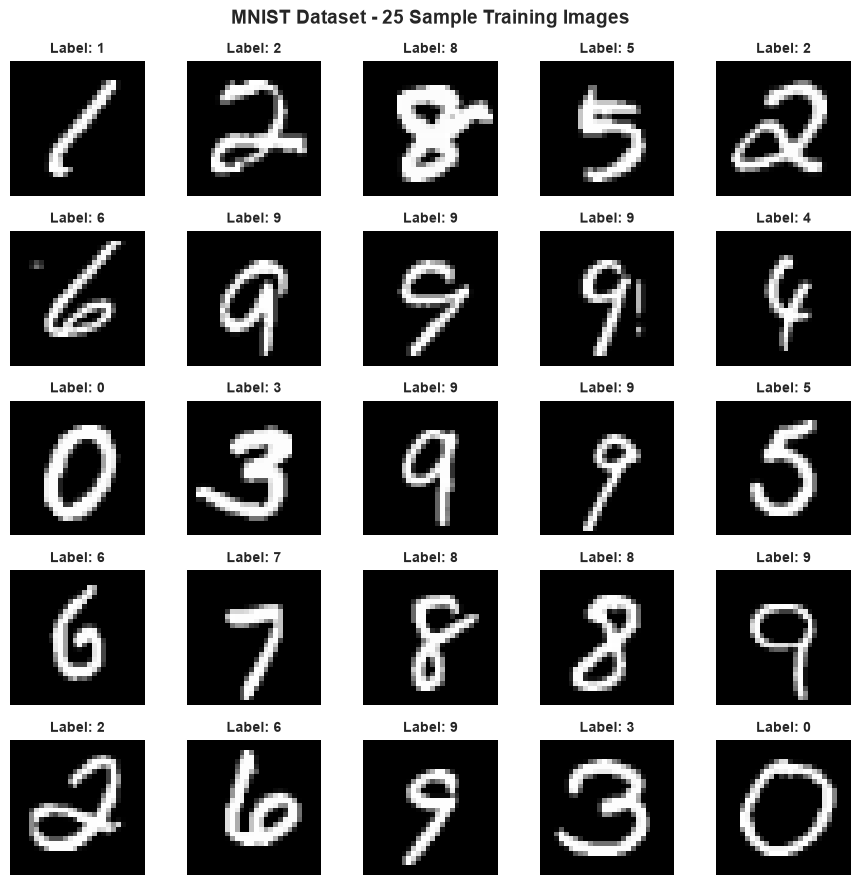

Saved 25 sample grid to plots/01_mnist_samples.png


In [4]:
dataiter = iter(train_loader)
images, labels = next(dataiter)

fig, axes = plt.subplots(5, 5, figsize=(9, 9))
fig.suptitle("MNIST Dataset - 25 Sample Training Images", fontsize=14, fontweight='bold', y=0.98)

mean, std = 0.1307, 0.3081

for i, ax in enumerate(axes.flat):
    img = images[i].numpy().squeeze() * std + mean
    ax.imshow(img, cmap='gray')
    ax.set_title(f"Label: {labels[i].item()}", fontsize=10, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.savefig('plots/01_mnist_samples.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved 25 sample grid to plots/01_mnist_samples.png")


## 2. Baseline Model (CNN)
Building the baseline Convolutional Neural Network with:
- Conv2d(1, 32, 3) -> ReLU -> MaxPool2d(2)
- Conv2d(32, 64, 3) -> ReLU -> MaxPool2d(2)
- Flatten -> Linear(1600, 128) -> ReLU -> Dropout(0.25) -> Linear(128, 10)


In [5]:
class BaselineCNN(nn.Module):
    def __init__(self, num_filters_conv1=32, dropout_rate=0.25):
        super(BaselineCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, num_filters_conv1, kernel_size=3)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(num_filters_conv1, 64, kernel_size=3)
        self.pool2 = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(64 * 5 * 5, 128)
        self.dropout = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool2(self.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

baseline_model = BaselineCNN().to(device)
print(baseline_model)


BaselineCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=1600, out_features=128, bias=True)
  (dropout): Dropout(p=0.25, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(baseline_model.parameters(), lr=0.001)

baseline_epoch_losses = []
epochs = 5

print("Training Baseline Model...")
start_time = time.time()

for epoch in range(epochs):
    baseline_model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = baseline_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
    
    epoch_loss = running_loss / len(train_loader.dataset)
    baseline_epoch_losses.append(epoch_loss)
    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f}")

print(f"Baseline Training completed in {time.time() - start_time:.2f} seconds.")


Training Baseline Model...
Epoch [1/5] - Loss: 0.1613
Epoch [2/5] - Loss: 0.0563
Epoch [3/5] - Loss: 0.0396
Epoch [4/5] - Loss: 0.0312
Epoch [5/5] - Loss: 0.0256
Baseline Training completed in 70.63 seconds.


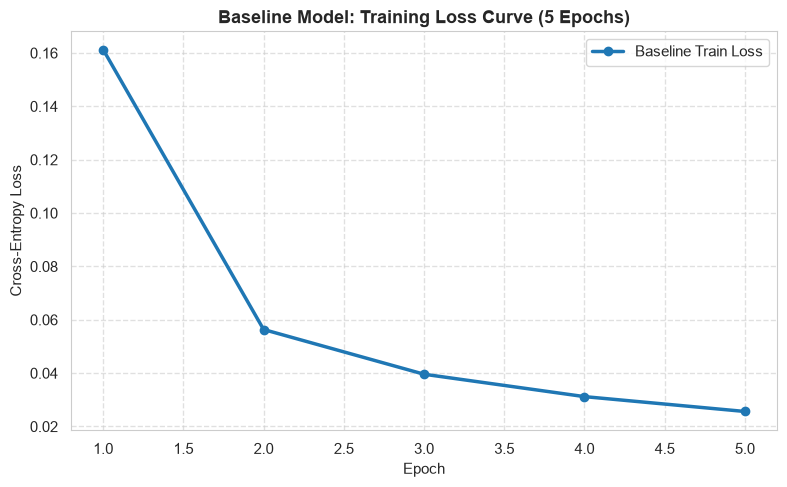

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), baseline_epoch_losses, marker='o', color='#1f77b4', linewidth=2.5, label='Baseline Train Loss')
plt.title("Baseline Model: Training Loss Curve (5 Epochs)", fontsize=13, fontweight='bold')
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Cross-Entropy Loss", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig('plots/02_baseline_loss_curve.png', dpi=300)
plt.show()


=== Baseline Model Evaluation Metrics ===
Test Accuracy:  99.11%
Precision:      0.9910
Recall:         0.9910
F1 Score:       0.9910


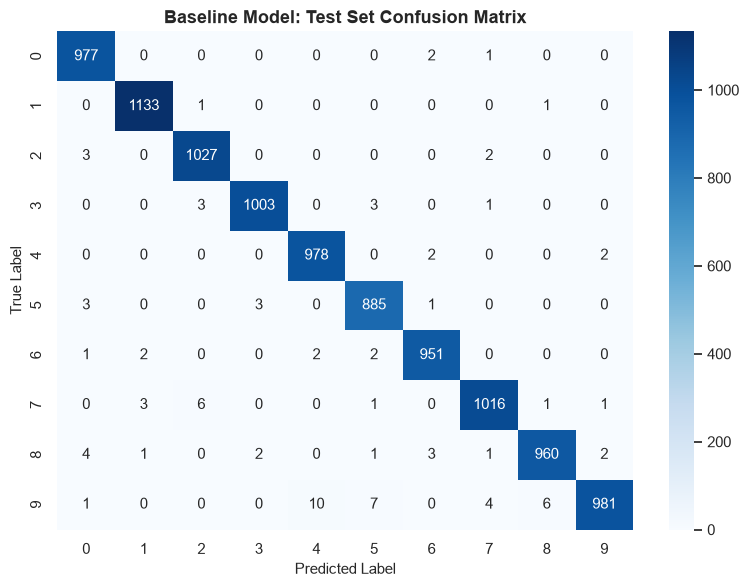

In [8]:
def evaluate_model(model, dataloader, device):
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []
    
    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
            all_probs.extend(probs.cpu().numpy())
            
    y_true = np.array(all_labels)
    y_pred = np.array(all_preds)
    y_prob = np.array(all_probs)
    
    acc = accuracy_score(y_true, y_pred)
    prec_macro = precision_score(y_true, y_pred, average='macro')
    rec_macro = recall_score(y_true, y_pred, average='macro')
    f1_macro = f1_score(y_true, y_pred, average='macro')
    
    return {
        'accuracy': acc,
        'precision_macro': prec_macro,
        'recall_macro': rec_macro,
        'f1_macro': f1_macro,
        'y_true': y_true,
        'y_pred': y_pred,
        'y_prob': y_prob
    }

baseline_metrics = evaluate_model(baseline_model, test_loader, device)

print(f"=== Baseline Model Evaluation Metrics ===")
print(f"Test Accuracy:  {baseline_metrics['accuracy'] * 100:.2f}%")
print(f"Precision:      {baseline_metrics['precision_macro']:.4f}")
print(f"Recall:         {baseline_metrics['recall_macro']:.4f}")
print(f"F1 Score:       {baseline_metrics['f1_macro']:.4f}")

# Plot Confusion Matrix
cm = confusion_matrix(baseline_metrics['y_true'], baseline_metrics['y_pred'])
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=range(10), yticklabels=range(10))
plt.title("Baseline Model: Test Set Confusion Matrix", fontsize=13, fontweight='bold')
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("True Label", fontsize=11)
plt.tight_layout()
plt.savefig('plots/03_baseline_confusion_matrix.png', dpi=300)
plt.show()


## 3. Cross-Validation (3-Fold on 15k Stratified Subset)

Cross-validation evaluates how well a model generalizes across different partitions of data, rather than relying on a single fixed train/validation split.
- **Bias**: Represents systemic error from overly restrictive model assumptions (underfitting). High bias results in poor training and validation accuracy alike.
- **Variance**: Measures sensitivity to fluctuations in training data. High variance manifests as strong training accuracy but poor/unstable validation performance across folds (overfitting).
- **Role of CV**: By computing the **mean** and **standard deviation** of validation performance across 3 folds, cross-validation provides an un-biased estimate of model generalization capability and variance.


In [9]:
targets = np.array(train_dataset.targets)

# Extract a 15k stratified subset
skf_subset = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)
subset_idx, _ = next(skf_subset.split(np.zeros(len(targets)), targets))
cv_subset_targets = targets[subset_idx]

skf_3fold = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
fold_accuracies = []

print("Executing 3-Fold Cross-Validation on 15k Stratified Subset...")

for fold, (train_idx, val_idx) in enumerate(skf_3fold.split(subset_idx, cv_subset_targets)):
    fold_train_sub = Subset(train_dataset, subset_idx[train_idx])
    fold_val_sub = Subset(train_dataset, subset_idx[val_idx])
    
    tr_ld = DataLoader(fold_train_sub, batch_size=64, shuffle=True)
    vl_ld = DataLoader(fold_val_sub, batch_size=64, shuffle=False)
    
    model_f = BaselineCNN().to(device)
    opt_f = optim.Adam(model_f.parameters(), lr=0.001)
    crit_f = nn.CrossEntropyLoss()
    
    for ep in range(3):
        model_f.train()
        for imgs, lbls in tr_ld:
            imgs, lbls = imgs.to(device), lbls.to(device)
            opt_f.zero_grad()
            loss = crit_f(model_f(imgs), lbls)
            loss.backward()
            opt_f.step()
            
    res_f = evaluate_model(model_f, vl_ld, device)
    acc_f = res_f['accuracy'] * 100
    fold_accuracies.append(acc_f)
    print(f"Fold {fold+1} Validation Accuracy: {acc_f:.2f}%")

cv_mean = np.mean(fold_accuracies)
cv_std = np.std(fold_accuracies)

print(f"\n3-Fold CV Results | Mean Accuracy: {cv_mean:.2f}% | Std Dev: {cv_std:.2f}%")


/var/folders/zd/zk7knhvs75xct76flnfyxrb00000gn/T/ipykernel_7183/1857365596.py:1: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  targets = np.array(train_dataset.targets)


Executing 3-Fold Cross-Validation on 15k Stratified Subset...
Fold 1 Validation Accuracy: 98.40%
Fold 2 Validation Accuracy: 98.55%
Fold 3 Validation Accuracy: 98.47%

3-Fold CV Results | Mean Accuracy: 98.47% | Std Dev: 0.06%


## 4. Hyperparameter Tuning — 3 Methods, 5 Hyperparameters

The 5 target hyperparameters tuned across methods:
1. `learning_rate`: `[0.01, 0.001, 0.0001]`
2. `batch_size`: `[32, 64, 128]`
3. `dropout_rate`: `[0.1, 0.25, 0.5]`
4. `num_filters_conv1`: `[16, 32, 64]`
5. `optimizer_type`: `['Adam', 'SGD']` (SGD uses momentum=0.9)


In [10]:
class ParameterizedCNN(nn.Module):
    def __init__(self, num_filters_conv1=32, dropout_rate=0.25):
        super(ParameterizedCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, num_filters_conv1, kernel_size=3)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(num_filters_conv1, 64, kernel_size=3)
        self.pool2 = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(64 * 5 * 5, 128)
        self.dropout = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool2(self.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

def train_and_eval_hyperparams(lr, batch_size, dropout_rate, num_filters_conv1, optimizer_type, epochs=2):
    tr_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    vl_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    
    model = ParameterizedCNN(num_filters_conv1=num_filters_conv1, dropout_rate=dropout_rate).to(device)
    criterion = nn.CrossEntropyLoss()
    
    if optimizer_type == 'Adam':
        optimizer = optim.Adam(model.parameters(), lr=lr)
    else:
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
        
    for epoch in range(epochs):
        model.train()
        for imgs, lbls in tr_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            optimizer.zero_grad()
            loss = criterion(model(imgs), lbls)
            loss.backward()
            optimizer.step()
            
    eval_res = evaluate_model(model, vl_loader, device)
    return eval_res['accuracy'] * 100


In [11]:
print("=== Method A: Grid Search (Manual Loop) ===")
grid_configs = [
    {'lr': 0.001,  'batch_size': 32,  'dropout': 0.25, 'filters': 32, 'opt': 'Adam'},
    {'lr': 0.001,  'batch_size': 64,  'dropout': 0.25, 'filters': 32, 'opt': 'Adam'},
    {'lr': 0.001,  'batch_size': 128, 'dropout': 0.25, 'filters': 32, 'opt': 'Adam'},
    {'lr': 0.01,   'batch_size': 32,  'dropout': 0.25, 'filters': 32, 'opt': 'Adam'},
    {'lr': 0.01,   'batch_size': 64,  'dropout': 0.25, 'filters': 32, 'opt': 'Adam'},
    {'lr': 0.01,   'batch_size': 128, 'dropout': 0.25, 'filters': 32, 'opt': 'Adam'},
    {'lr': 0.0001, 'batch_size': 32,  'dropout': 0.25, 'filters': 32, 'opt': 'Adam'},
    {'lr': 0.0001, 'batch_size': 64,  'dropout': 0.25, 'filters': 32, 'opt': 'Adam'},
    {'lr': 0.0001, 'batch_size': 128, 'dropout': 0.25, 'filters': 32, 'opt': 'Adam'},
    {'lr': 0.001,  'batch_size': 64,  'dropout': 0.1,  'filters': 16, 'opt': 'Adam'},
    {'lr': 0.001,  'batch_size': 64,  'dropout': 0.5,  'filters': 64, 'opt': 'Adam'},
    {'lr': 0.01,   'batch_size': 64,  'dropout': 0.25, 'filters': 32, 'opt': 'SGD'}
]

grid_results = []

for i, cfg in enumerate(grid_configs):
    val_acc = train_and_eval_hyperparams(
        lr=cfg['lr'],
        batch_size=cfg['batch_size'],
        dropout_rate=cfg['dropout'],
        num_filters_conv1=cfg['filters'],
        optimizer_type=cfg['opt'],
        epochs=3
    )
    res = {**cfg, 'val_acc': val_acc, 'config_name': f"Grid_{i+1}"}
    grid_results.append(res)
    print(f"Grid Config {i+1:02d}: LR={cfg['lr']}, Batch={cfg['batch_size']}, Dropout={cfg['dropout']}, Filters={cfg['filters']}, Opt={cfg['opt']} -> Val Acc: {val_acc:.2f}%")

df_grid = pd.DataFrame(grid_results)
best_grid = df_grid.loc[df_grid['val_acc'].idxmax()]
print(f"\nBest Grid Search Config: {best_grid['config_name']} with Val Acc = {best_grid['val_acc']:.2f}%")


=== Method A: Grid Search (Manual Loop) ===
Grid Config 01: LR=0.001, Batch=32, Dropout=0.25, Filters=32, Opt=Adam -> Val Acc: 99.02%
Grid Config 02: LR=0.001, Batch=64, Dropout=0.25, Filters=32, Opt=Adam -> Val Acc: 98.79%
Grid Config 03: LR=0.001, Batch=128, Dropout=0.25, Filters=32, Opt=Adam -> Val Acc: 99.07%


/Users/badrootz/eVantage/sapt4/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Grid Config 04: LR=0.01, Batch=32, Dropout=0.25, Filters=32, Opt=Adam -> Val Acc: 11.35%
Grid Config 05: LR=0.01, Batch=64, Dropout=0.25, Filters=32, Opt=Adam -> Val Acc: 96.61%
Grid Config 06: LR=0.01, Batch=128, Dropout=0.25, Filters=32, Opt=Adam -> Val Acc: 98.04%
Grid Config 07: LR=0.0001, Batch=32, Dropout=0.25, Filters=32, Opt=Adam -> Val Acc: 98.58%
Grid Config 08: LR=0.0001, Batch=64, Dropout=0.25, Filters=32, Opt=Adam -> Val Acc: 98.28%
Grid Config 09: LR=0.0001, Batch=128, Dropout=0.25, Filters=32, Opt=Adam -> Val Acc: 98.00%
Grid Config 10: LR=0.001, Batch=64, Dropout=0.1, Filters=16, Opt=Adam -> Val Acc: 99.04%
Grid Config 11: LR=0.001, Batch=64, Dropout=0.5, Filters=64, Opt=Adam -> Val Acc: 99.03%
Grid Config 12: LR=0.01, Batch=64, Dropout=0.25, Filters=32, Opt=SGD -> Val Acc: 99.03%

Best Grid Search Config: Grid_3 with Val Acc = 99.07%


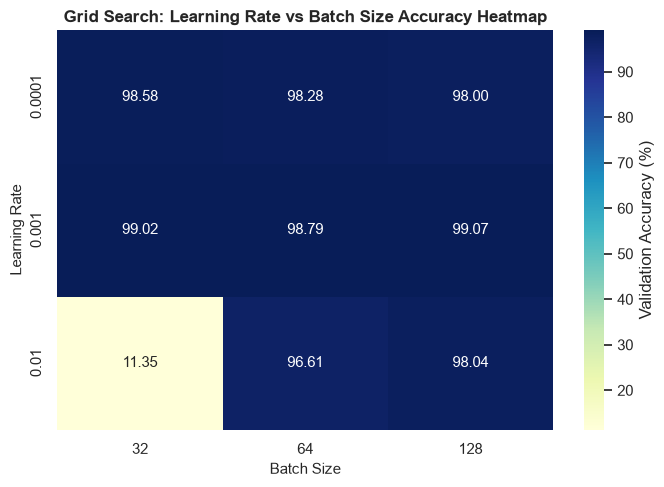

In [12]:
sub_grid = df_grid[(df_grid['dropout'] == 0.25) & (df_grid['filters'] == 32) & (df_grid['opt'] == 'Adam')]
pivot_grid = sub_grid.pivot(index='lr', columns='batch_size', values='val_acc')

plt.figure(figsize=(7, 5))
sns.heatmap(pivot_grid, annot=True, fmt='.2f', cmap='YlGnBu', cbar_kws={'label': 'Validation Accuracy (%)'})
plt.title("Grid Search: Learning Rate vs Batch Size Accuracy Heatmap", fontsize=12, fontweight='bold')
plt.xlabel("Batch Size", fontsize=11)
plt.ylabel("Learning Rate", fontsize=11)
plt.tight_layout()
plt.savefig('plots/04_grid_search_heatmap.png', dpi=300)
plt.show()


In [13]:
print("=== Method B: Random Search (Manual Loop) ===")
search_space = {
    'lr': [0.01, 0.001, 0.0001],
    'batch_size': [32, 64, 128],
    'dropout': [0.1, 0.25, 0.5],
    'filters': [16, 32, 64],
    'opt': ['Adam', 'SGD']
}

random_results = []
set_seed(101)

for i in range(10):
    cfg = {
        'lr': float(np.random.choice(search_space['lr'])),
        'batch_size': int(np.random.choice(search_space['batch_size'])),
        'dropout': float(np.random.choice(search_space['dropout'])),
        'filters': int(np.random.choice(search_space['filters'])),
        'opt': str(np.random.choice(search_space['opt']))
    }
    val_acc = train_and_eval_hyperparams(
        lr=cfg['lr'],
        batch_size=cfg['batch_size'],
        dropout_rate=cfg['dropout'],
        num_filters_conv1=cfg['filters'],
        optimizer_type=cfg['opt'],
        epochs=3
    )
    res = {**cfg, 'val_acc': val_acc, 'config_name': f"Random_{i+1}"}
    random_results.append(res)
    print(f"Random Config {i+1:02d}: LR={cfg['lr']}, Batch={cfg['batch_size']}, Dropout={cfg['dropout']}, Filters={cfg['filters']}, Opt={cfg['opt']} -> Val Acc: {val_acc:.2f}%")

df_random = pd.DataFrame(random_results)
best_random = df_random.loc[df_random['val_acc'].idxmax()]
print(f"\nBest Random Search Config: {best_random['config_name']} with Val Acc = {best_random['val_acc']:.2f}%")
print(f"Grid vs Random Best Accuracy: Grid Search ({best_grid['val_acc']:.2f}%) vs Random Search ({best_random['val_acc']:.2f}%)")


=== Method B: Random Search (Manual Loop) ===
Random Config 01: LR=0.001, Batch=128, Dropout=0.25, Filters=32, Opt=SGD -> Val Acc: 96.32%
Random Config 02: LR=0.01, Batch=32, Dropout=0.1, Filters=32, Opt=Adam -> Val Acc: 94.98%
Random Config 03: LR=0.01, Batch=32, Dropout=0.5, Filters=32, Opt=Adam -> Val Acc: 94.89%
Random Config 04: LR=0.001, Batch=32, Dropout=0.25, Filters=64, Opt=Adam -> Val Acc: 98.93%
Random Config 05: LR=0.001, Batch=128, Dropout=0.1, Filters=16, Opt=SGD -> Val Acc: 95.87%
Random Config 06: LR=0.0001, Batch=128, Dropout=0.1, Filters=16, Opt=SGD -> Val Acc: 82.38%
Random Config 07: LR=0.001, Batch=32, Dropout=0.5, Filters=16, Opt=SGD -> Val Acc: 98.09%
Random Config 08: LR=0.01, Batch=128, Dropout=0.1, Filters=16, Opt=SGD -> Val Acc: 98.51%
Random Config 09: LR=0.0001, Batch=128, Dropout=0.25, Filters=16, Opt=Adam -> Val Acc: 97.85%
Random Config 10: LR=0.01, Batch=32, Dropout=0.1, Filters=64, Opt=Adam -> Val Acc: 94.04%

Best Random Search Config: Random_4 with V

In [14]:
print("=== Method C: Bayesian Optimization (Optuna) ===")
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    lr = trial.suggest_categorical('lr', [0.0001, 0.001, 0.01])
    batch_size = trial.suggest_categorical('batch_size', [32, 64, 128])
    dropout = trial.suggest_categorical('dropout', [0.1, 0.25, 0.5])
    filters = trial.suggest_categorical('filters', [16, 32, 64])
    opt_type = trial.suggest_categorical('opt', ['Adam', 'SGD'])
    
    val_acc = train_and_eval_hyperparams(
        lr=lr,
        batch_size=batch_size,
        dropout_rate=dropout,
        num_filters_conv1=filters,
        optimizer_type=opt_type,
        epochs=3
    )
    return val_acc

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=15)

print(f"Optuna Best Trial #{study.best_trial.number + 1} | Val Accuracy: {study.best_value:.2f}%")
print(f"Best Hyperparameters: {study.best_params}")


=== Method C: Bayesian Optimization (Optuna) ===


/Users/badrootz/eVantage/sapt4/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Optuna Best Trial #2 | Val Accuracy: 99.07%
Best Hyperparameters: {'lr': 0.01, 'batch_size': 32, 'dropout': 0.1, 'filters': 64, 'opt': 'SGD'}


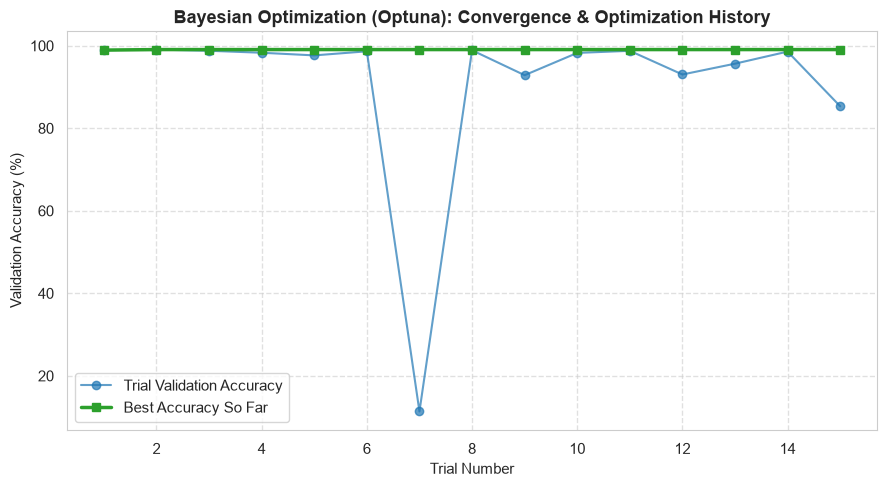

In [15]:
trial_numbers = [t.number + 1 for t in study.trials]
trial_values = [t.value for t in study.trials]
best_values = np.maximum.accumulate(trial_values)

plt.figure(figsize=(9, 5))
plt.plot(trial_numbers, trial_values, marker='o', color='#1f77b4', alpha=0.7, label='Trial Validation Accuracy')
plt.plot(trial_numbers, best_values, marker='s', color='#2ca02c', linewidth=2.5, label='Best Accuracy So Far')
plt.title("Bayesian Optimization (Optuna): Convergence & Optimization History", fontsize=13, fontweight='bold')
plt.xlabel("Trial Number", fontsize=11)
plt.ylabel("Validation Accuracy (%)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig('plots/05_bayesian_optimization_history.png', dpi=300)
plt.show()


## 5. Final Model Training & Comprehensive Evaluation

In [16]:
best_config = study.best_params
print("Selected Best Hyperparameters across all 3 methods:")
for k, v in best_config.items():
    print(f"  {k}: {v}")

final_train_loader = DataLoader(train_dataset, batch_size=best_config['batch_size'], shuffle=True)
final_test_loader = DataLoader(test_dataset, batch_size=best_config['batch_size'], shuffle=False)

final_model = ParameterizedCNN(
    num_filters_conv1=best_config['filters'],
    dropout_rate=best_config['dropout']
).to(device)

criterion = nn.CrossEntropyLoss()
if best_config['opt'] == 'Adam':
    optimizer = optim.Adam(final_model.parameters(), lr=best_config['lr'])
else:
    optimizer = optim.SGD(final_model.parameters(), lr=best_config['lr'], momentum=0.9)

final_train_losses = []
final_val_accs = []
final_epochs = 10

print("\nTraining Final Tuned Model for 10 Epochs...")
start_time = time.time()

for epoch in range(final_epochs):
    final_model.train()
    running_loss = 0.0
    for images, labels in final_train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = final_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        
    epoch_loss = running_loss / len(final_train_loader.dataset)
    final_train_losses.append(epoch_loss)
    
    val_res = evaluate_model(final_model, final_test_loader, device)
    final_val_accs.append(val_res['accuracy'] * 100)
    
    print(f"Epoch [{epoch+1:02d}/{final_epochs}] - Train Loss: {epoch_loss:.4f} | Test Acc: {val_res['accuracy']*100:.2f}%")

print(f"Final Model Training Completed in {time.time() - start_time:.2f} seconds.")


Selected Best Hyperparameters across all 3 methods:
  lr: 0.01
  batch_size: 32
  dropout: 0.1
  filters: 64
  opt: SGD

Training Final Tuned Model for 10 Epochs...
Epoch [01/10] - Train Loss: 0.1426 | Test Acc: 98.47%
Epoch [02/10] - Train Loss: 0.0463 | Test Acc: 98.99%
Epoch [03/10] - Train Loss: 0.0331 | Test Acc: 99.10%
Epoch [04/10] - Train Loss: 0.0235 | Test Acc: 98.69%
Epoch [05/10] - Train Loss: 0.0184 | Test Acc: 99.15%
Epoch [06/10] - Train Loss: 0.0138 | Test Acc: 99.10%
Epoch [07/10] - Train Loss: 0.0120 | Test Acc: 99.12%
Epoch [08/10] - Train Loss: 0.0096 | Test Acc: 99.21%
Epoch [09/10] - Train Loss: 0.0067 | Test Acc: 99.32%
Epoch [10/10] - Train Loss: 0.0072 | Test Acc: 99.07%
Final Model Training Completed in 228.92 seconds.


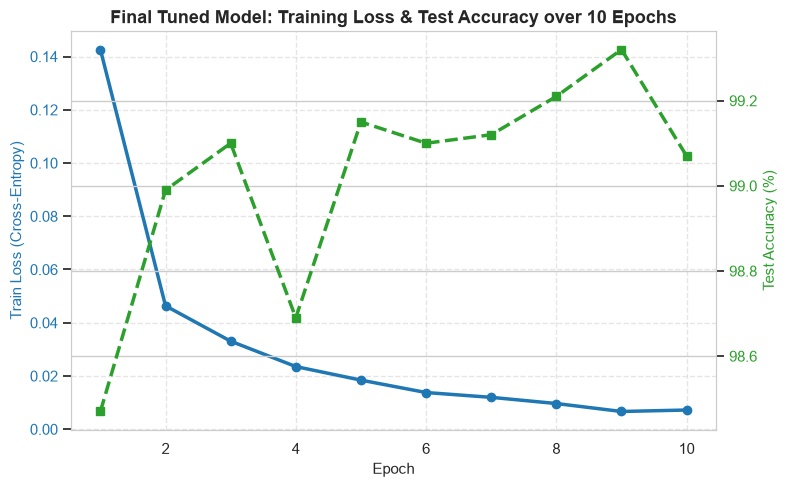

In [17]:
fig, ax1 = plt.subplots(figsize=(8, 5))

color = '#1f77b4'
ax1.set_xlabel('Epoch', fontsize=11)
ax1.set_ylabel('Train Loss (Cross-Entropy)', color=color, fontsize=11)
ax1.plot(range(1, final_epochs + 1), final_train_losses, color=color, marker='o', linewidth=2.5, label='Train Loss')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()  
color = '#2ca02c'
ax2.set_ylabel('Test Accuracy (%)', color=color, fontsize=11)
ax2.plot(range(1, final_epochs + 1), final_val_accs, color=color, marker='s', linewidth=2.5, linestyle='--', label='Test Accuracy')
ax2.tick_params(axis='y', labelcolor=color)

plt.title("Final Tuned Model: Training Loss & Test Accuracy over 10 Epochs", fontsize=13, fontweight='bold')
fig.tight_layout()
plt.savefig('plots/06_final_model_loss.png', dpi=300)
plt.show()


=== Final Tuned Model Evaluation Metrics ===
Test Accuracy:     99.07%
Precision (Macro): 0.9908
Recall (Macro):    0.9906
F1 Score (Macro):  0.9907


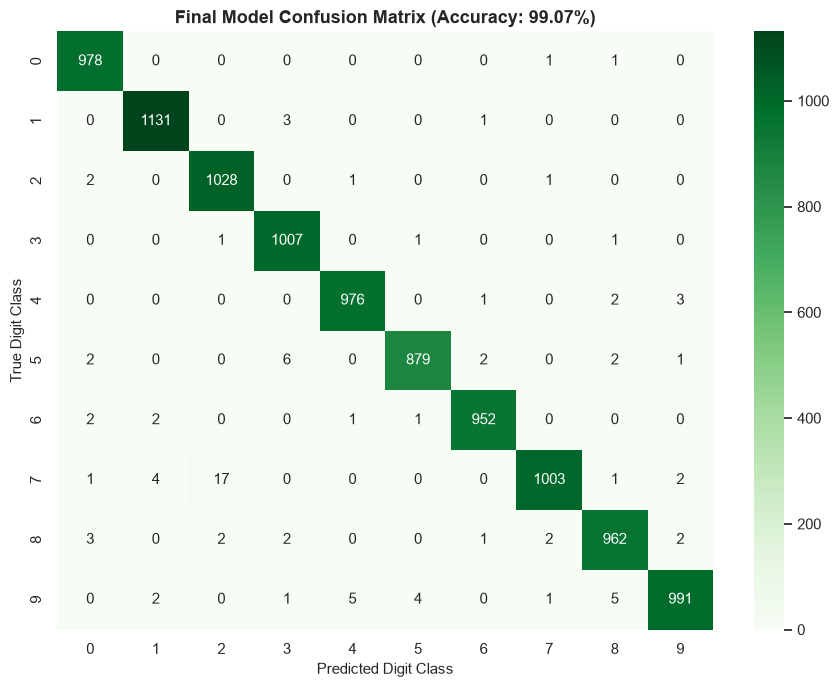

In [18]:
final_metrics = evaluate_model(final_model, final_test_loader, device)

print("=== Final Tuned Model Evaluation Metrics ===")
print(f"Test Accuracy:     {final_metrics['accuracy'] * 100:.2f}%")
print(f"Precision (Macro): {final_metrics['precision_macro']:.4f}")
print(f"Recall (Macro):    {final_metrics['recall_macro']:.4f}")
print(f"F1 Score (Macro):  {final_metrics['f1_macro']:.4f}")

# Plot Confusion Matrix
cm_final = confusion_matrix(final_metrics['y_true'], final_metrics['y_pred'])
plt.figure(figsize=(9, 7))
sns.heatmap(cm_final, annot=True, fmt='d', cmap='Greens', cbar=True,
            xticklabels=range(10), yticklabels=range(10))
plt.title(f"Final Model Confusion Matrix (Accuracy: {final_metrics['accuracy']*100:.2f}%)", fontsize=13, fontweight='bold')
plt.xlabel("Predicted Digit Class", fontsize=11)
plt.ylabel("True Digit Class", fontsize=11)
plt.tight_layout()
plt.savefig('plots/07_final_confusion_matrix.png', dpi=300)
plt.show()


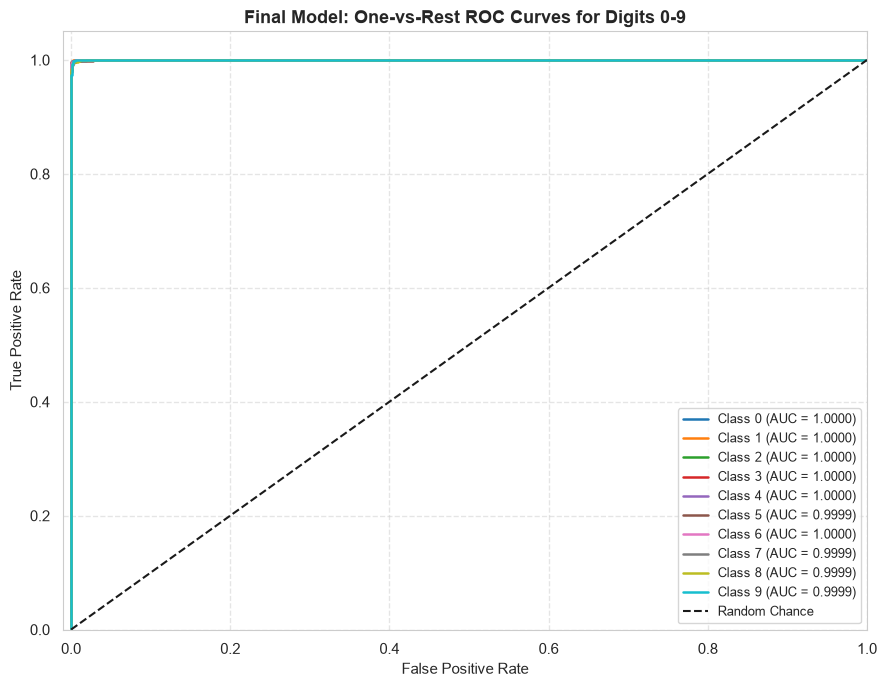

In [19]:
from sklearn.preprocessing import label_binarize
y_test_bin = label_binarize(final_metrics['y_true'], classes=list(range(10)))
y_score = final_metrics['y_prob']

plt.figure(figsize=(9, 7))
colors = plt.cm.tab10(np.linspace(0, 1, 10))

for i in range(10):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=colors[i], lw=1.8, label=f'Class {i} (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Chance')
plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.title('Final Model: One-vs-Rest ROC Curves for Digits 0-9', fontsize=13, fontweight='bold')
plt.legend(loc="lower right", fontsize=9)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('plots/08_final_roc_curves.png', dpi=300)
plt.show()


In [20]:
model_save_path = "mnist_final_model.pth"
torch.save(final_model.state_dict(), model_save_path)
print(f"Final trained PyTorch model state_dict saved to '{model_save_path}'. File size: {os.path.getsize(model_save_path)/1024:.2f} KB.")


Final trained PyTorch model state_dict saved to 'mnist_final_model.pth'. File size: 955.96 KB.


## 6. Performance Improvement Log

,Config,Method,LR,Batch,Dropout,Filters,Optimizer,Val Acc (%)
0,Baseline CNN,Baseline,0.0010,64,0.25,32,Adam,99.11
1,Grid_3,Grid Search,0.0010,128,0.25,32,Adam,99.07
2,Optuna Trial 2,Bayesian Opt,0.0100,32,0.10,64,SGD,99.07
3,Final Model (10 eps),Final Tuned,0.0100,32,0.10,64,SGD,99.07
4,Grid_10,Grid Search,0.0010,64,0.10,16,Adam,99.04
5,Grid_11,Grid Search,0.0010,64,0.50,64,Adam,99.03
6,Grid_12,Grid Search,0.0100,64,0.25,32,SGD,99.03
7,Grid_1,Grid Search,0.0010,32,0.25,32,Adam,99.02
8,Optuna Trial 1,Bayesian Opt,0.0010,32,0.25,64,Adam,98.94
9,Random_4,Random Search,0.0010,32,0.25,64,Adam,98.93


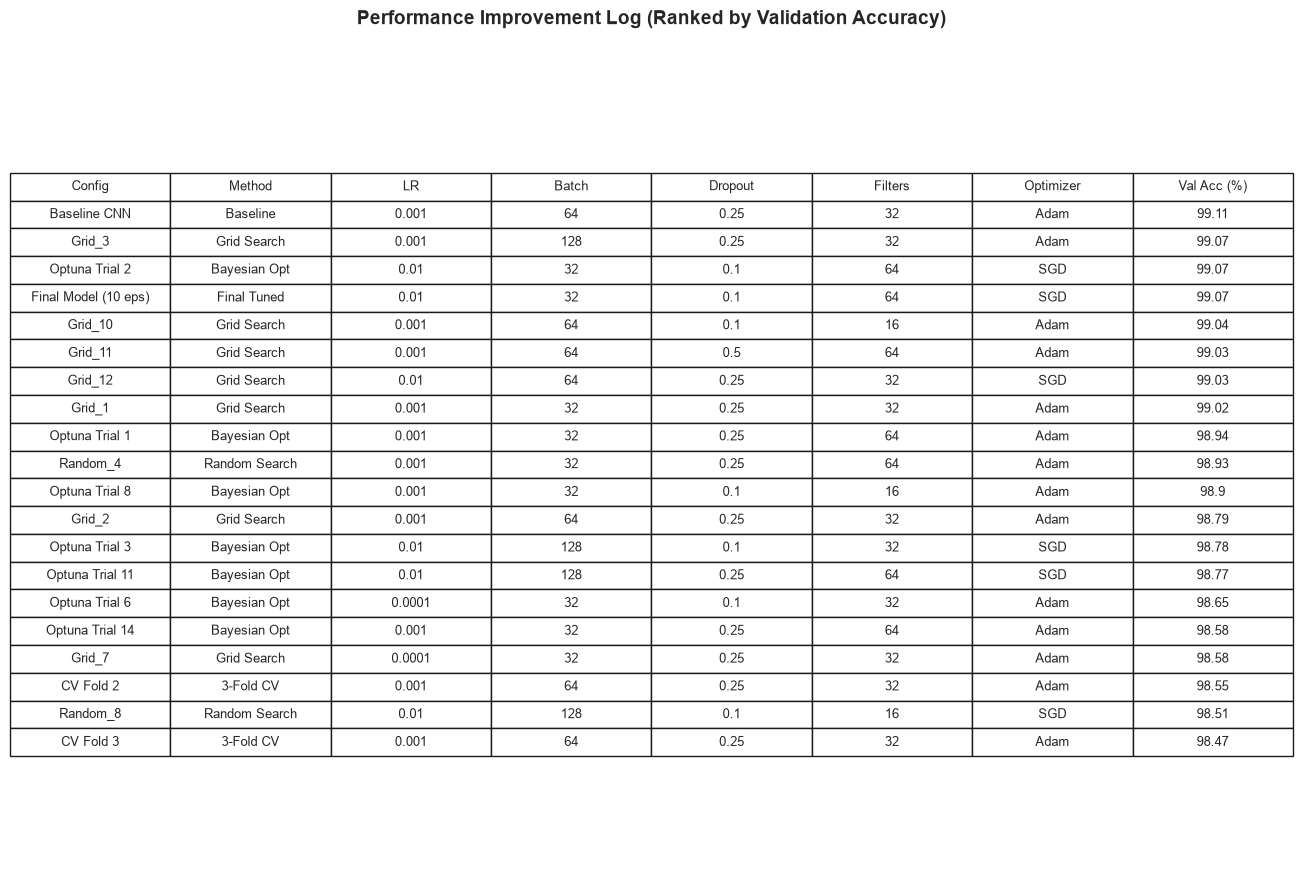

In [21]:
all_logs = []

# Baseline
all_logs.append({
    'Config': 'Baseline CNN', 'Method': 'Baseline',
    'LR': 0.001, 'Batch': 64, 'Dropout': 0.25, 'Filters': 32, 'Optimizer': 'Adam',
    'Val Acc (%)': round(baseline_metrics['accuracy'] * 100, 2)
})

# CV Folds
for idx, f_acc in enumerate(fold_accuracies):
    all_logs.append({
        'Config': f'CV Fold {idx+1}', 'Method': '3-Fold CV',
        'LR': 0.001, 'Batch': 64, 'Dropout': 0.25, 'Filters': 32, 'Optimizer': 'Adam',
        'Val Acc (%)': round(f_acc, 2)
    })

# Grid Search
for g in grid_results:
    all_logs.append({
        'Config': g['config_name'], 'Method': 'Grid Search',
        'LR': g['lr'], 'Batch': g['batch_size'], 'Dropout': g['dropout'], 'Filters': g['filters'], 'Optimizer': g['opt'],
        'Val Acc (%)': round(g['val_acc'], 2)
    })

# Random Search
for r in random_results:
    all_logs.append({
        'Config': r['config_name'], 'Method': 'Random Search',
        'LR': r['lr'], 'Batch': r['batch_size'], 'Dropout': r['dropout'], 'Filters': r['filters'], 'Optimizer': r['opt'],
        'Val Acc (%)': round(r['val_acc'], 2)
    })

# Optuna Trials
for t in study.trials:
    all_logs.append({
        'Config': f'Optuna Trial {t.number+1}', 'Method': 'Bayesian Opt',
        'LR': t.params['lr'], 'Batch': t.params['batch_size'], 'Dropout': t.params['dropout'],
        'Filters': t.params['filters'], 'Optimizer': t.params['opt'],
        'Val Acc (%)': round(t.value, 2)
    })

# Final Model
all_logs.append({
    'Config': 'Final Model (10 eps)', 'Method': 'Final Tuned',
    'LR': best_config['lr'], 'Batch': best_config['batch_size'], 'Dropout': best_config['dropout'],
    'Filters': best_config['filters'], 'Optimizer': best_config['opt'],
    'Val Acc (%)': round(final_metrics['accuracy'] * 100, 2)
})

df_log = pd.DataFrame(all_logs)
df_log_sorted = df_log.sort_values(by='Val Acc (%)', ascending=False).reset_index(drop=True)

# Display table
display(df_log_sorted.head(20))

# Render summary table image
fig, ax = plt.subplots(figsize=(13, 9))
ax.axis('tight')
ax.axis('off')
top_table_df = df_log_sorted.head(20)
table = ax.table(cellText=top_table_df.values, colLabels=top_table_df.columns, cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.1, 1.4)
plt.title("Performance Improvement Log (Ranked by Validation Accuracy)", fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('plots/09_performance_improvement_log.png', dpi=300, bbox_inches='tight')
plt.show()
